In [2]:
import scimap as sm

Running SCIMAP  2.3.4


In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import anndata as ad
import scanpy as sc

In [4]:
import os
os.getcwd()

'C:\\Users\\tpeng\\Documents\\Spatial\\notebook'

## download the adata object "Xenium_Proseq_pt3_lesion_neighborhood_261009.h5ad" from the GitHub page"

In [57]:
adata = sc.read ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt3_lesion_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 11072 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'leiden', 'barcodes', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    layers: 'counts'

In [30]:
# run the LDA tool
adata = sm.tl.spatial_lda(adata, phenotype='Cell_label_L3', method='radius', radius=80, label='spatial_lda')

Processing: ['LGlesion_proseq']
Identifying neighbours within 80 pixels of every cell
Pre-Processing Spatial LDA
Training Spatial LDA
Calculating the Coherence Score

Coherence Score:  0.21940586459023675
Gathering the latent weights


C:\Users\tpeng\anaconda3\envs\scimap\lib\site-packages\scimap\tools\spatial_lda.py:270: ImplicitModificationWarning:

Trying to modify attribute `._uns` of view, initializing view as actual.



In [31]:
adata

AnnData object with n_obs × n_vars = 11072 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'SampleID', 'Tissue_type', 'PatientID', 'n_counts', 'leiden', 'barcodes', 'leiden3', 'Cell_label_L3', 'imageid'
    uns: 'Cell_label_L3_colors', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    layers: 'counts'

## try 6 clusters 1st time ##

In [33]:
# note that the df_name parameter needs to be the same as the label used in the previous step.
adata = sm.tl.spatial_cluster(adata, df_name='spatial_lda', method='kmeans', k=6, label='spatial_lda_kmeans6')

Kmeans clustering


In [34]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.colors as mcolors

In [51]:
# Let's visualize the results.

from matplotlib import rcParams
FIGSIZE = (16, 16)
my_colors = {'0':'yellowgreen', '1':'lightsalmon', '2':'olive', '3':'rosybrown', '4':'purple','5' : 'lightsteelblue'}

sm.pl.spatial_scatterPlot(adata, colorBy='spatial_lda_kmeans6', s =4, alpha = 0.8,  dpi = 300,customColors = my_colors,
                          fileName='scatterplot_pt3_lesion_IC+kera_6clusters_261009.png', saveDir="./figures")

Saved plot to ./figures\scatterplot_pt3_lesion_IC+kera_6clusters_261009.png


In [67]:
adata.write_h5ad ('C:\\Users\\tpeng\\\Documents\\Spatial\\adata_files\\Xenium_Proseq_pt3_lesion_neighborhood_261009.h5ad')

In [69]:
adata

AnnData object with n_obs × n_vars = 11072 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'leiden', 'barcodes', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    layers: 'counts'

In [71]:
adata.obs.imageid.unique()

['Pt3_lesion_proseq']
Categories (1, object): ['Pt3_lesion_proseq']

## Generate heatmap ##

In [2]:
adata = sc.read ('C:\\Users\\tpeng\\adata_files\\Xenium_Proseq_pt3_lesion_neighborhood_261009.h5ad')
adata

AnnData object with n_obs × n_vars = 11072 × 475
    obs: 'cell', 'X_centroid', 'Y_centroid', 'centroid_z', 'fov', 'cluster', 'volume', 'population', 'Tissue_type', 'n_counts', 'leiden', 'barcodes', 'Cell_label_L3', 'imageid', 'spatial_lda_kmeans6'
    uns: 'Cell_label_L3_colors', 'spatial_lda', 'spatial_lda_probability'
    obsm: 'X_pca', 'X_umap', 'spatial'
    layers: 'counts'

In [3]:
adata.obs.imageid.unique()

['Pt3_lesion_proseq']
Categories (1, object): ['Pt3_lesion_proseq']

In [4]:
df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()
df

C:\Users\tpeng\AppData\Local\Temp\ipykernel_11664\545790267.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df = adata.obs.groupby("Cell_label_L3")["spatial_lda_kmeans6"].value_counts().unstack()


spatial_lda_kmeans6,0,1,2,3,4,5
Cell_label_L3,,,,,,
Basal keratinocyte_lesion,28,4,84,335,1,4
Basal keratinocyte_non-lesion,98,13,628,51,1,25
CD4 T cell_FOXP3+,94,179,38,28,162,78
CD4 T cell_GZMBhi,32,22,15,15,53,24
CD4 T cell_GZMBlow,74,376,5,4,74,79
CD8 T cell_GZMBhi,72,51,58,48,164,31
CD8 T cell_GZMBlow,49,287,11,5,54,38
DC,136,84,28,88,147,39
DC_LAMP3+,31,23,1,16,64,29


In [5]:
frequency_table = (df / df.sum())*100
pd.options.display.float_format = '{:.2f}'.format

In [6]:
custom_order = ['3', '4', '1','2','0','5']
frequency_table = frequency_table[custom_order]

In [7]:
frequency_table.columns = ['N0','N1','N2','N3','N4','N5']

In [8]:
# Replace specific elements using a dictionary
frequency_table.index = frequency_table.index.rename_categories({
                                                       'Basal keratinocyte_lesion' : 'Basal keratinocyte_ulc',
                                                       'Basal keratinocyte_non-lesion' : 'Basal keratinocyte_adj'})

In [9]:
frequency_table

,N0,N1,N2,N3,N4,N5
Cell_label_L3,,,,,,
Basal keratinocyte_ulc,13.83,0.05,0.23,5.37,1.53,0.28
Basal keratinocyte_adj,2.11,0.05,0.75,40.13,5.34,1.75
CD4 T cell_FOXP3+,1.16,7.75,10.33,2.43,5.12,5.47
CD4 T cell_GZMBhi,0.62,2.53,1.27,0.96,1.74,1.68
CD4 T cell_GZMBlow,0.17,3.54,21.71,0.32,4.03,5.54
CD8 T cell_GZMBhi,1.98,7.84,2.94,3.71,3.92,2.17
CD8 T cell_GZMBlow,0.21,2.58,16.57,0.70,2.67,2.66
DC,3.63,7.03,4.85,1.79,7.41,2.73
DC_LAMP3+,0.66,3.06,1.33,0.06,1.69,2.03


In [10]:
list2 = ['Granulosum keratinocyte_CXCL8+',
 'Spinosum keratinocyte_CXCL8+',
 'Basal keratinocyte_ulc',
 'Granulosum keratinocyte_KRT2+',
 'Spinosum keratinocyte_KRT2+',
 'Basal keratinocyte_adj',
 'CD8 T cell_GZMBhi',
 'CD4 T cell_GZMBhi',
 'CD8 T cell_GZMBlow',
 'CD4 T cell_GZMBlow',
 'CD4 T cell_FOXP3+',
 'NK cell',
 'Mono_IL3RA+',
 'Mono_ISGhi','Mono_ISGlow',
 'Mac_IL3RA+',
 'Mac_ISGlow',
 'DC_LAMP3+',
 'DC',
 'PDC']

In [11]:
# Define your desired custom order
custom_order = list2
# Reorder the index based on the list
frequency_table = frequency_table.reindex(custom_order)

In [13]:
frequency_table.index = ['Granu kera_CXCL8+',
 'Spino kera_CXCL8+',
 'Basa kera_ulc',
 'Granu kera_KRT2+',
 'Spino kera_KRT2+',
 'Basa kera_adj',
 'CD8 T_GZMBhi',
 'CD4 T_GZMBhi',
 'CD8 T_GZMBlow','CD4 T_GZMBlow',
 'CD4 T_FOXP3+',
 'NK',
 'Mono_IL3RA+',
 'Mono_ISGhi','Mono_ISGlow',
 'Mac_IL3RA+','Mac_ISGlow',
 'DC_LAMP3+',
 'DC',
 'PDC']

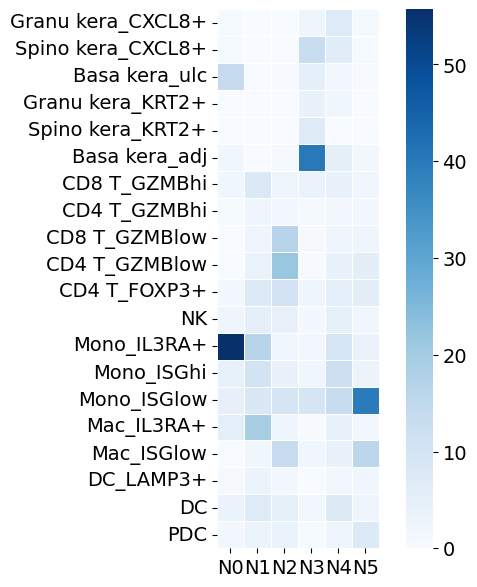

In [14]:
plt.figure(figsize=(7, 7)) # Optional: Adjust the size of the plot

ax = sns.heatmap(
    data= frequency_table,          # The DataFrame/data to plot
    annot=False,               # Display the correlation values on the heatmap
    cmap='Blues',          # The color map (e.g., 'viridis', 'plasma', 'coolwarm')
    fmt=".2f",                # String format for annotation values
    linewidths=.5,            # Space between cells
    annot_kws={"fontsize": 16}, square = True
)


# Set the font size for the x and y tick labels
ax.set_xticklabels(ax.get_xticklabels(), fontsize=14)
ax.set_yticklabels(ax.get_yticklabels(), fontsize=14)


# Access the colorbar and set the size of its tick labels
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14) # 'labelsize' parameter sets the tick label font size

plt.show()

In [15]:
adata.obs.imageid.unique()

['Pt3_lesion_proseq']
Categories (1, object): ['Pt3_lesion_proseq']